In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
pd.set_option("display.max_columns", None)

In [3]:
production = pd.read_parquet(
    "../datasets/modeling/production_dataset_training.parquet"
)

production.head()

,State,District_Name,Year,Season,Crop,Area,Production,Yield,Avg_Annual_Temperature,Avg_Annual_DewPoint,Total_Annual_Rainfall,Avg_Annual_Wind_Speed,Avg_Annual_Surface_Pressure,Avg_Grid_Points
0,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Arecanut,1254.0,2000.0,1.594896,26.79281,23.292879,84.931473,4.373926,1006.624207,10.0
1,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Other Kharif Pulses,2.0,1.0,0.500000,26.79281,23.292879,84.931473,4.373926,1006.624207,10.0
2,Andaman And Nicobar Islands,Nicobars,2000,Kharif,Rice,102.0,321.0,3.147059,26.79281,23.292879,84.931473,4.373926,1006.624207,10.0
3,Andaman And Nicobar Islands,Nicobars,2000,Whole Year,Banana,176.0,641.0,3.642045,26.79281,23.292879,84.931473,4.373926,1006.624207,10.0
4,Andaman And Nicobar Islands,Nicobars,2000,Whole Year,Cashewnut,720.0,165.0,0.229167,26.79281,23.292879,84.931473,4.373926,1006.624207,10.0


In [6]:
production.isnull().sum()

State                          0
District_Name                  0
Year                           0
Season                         0
Crop                           0
Area                           0
Production                     0
Yield                          0
Avg_Annual_Temperature         0
Avg_Annual_DewPoint            0
Total_Annual_Rainfall          0
Avg_Annual_Wind_Speed          0
Avg_Annual_Surface_Pressure    0
Avg_Grid_Points                0
dtype: int64

In [7]:
production.describe()

,Year,Area,Production,Yield,Avg_Annual_Temperature,Avg_Annual_DewPoint,Total_Annual_Rainfall,Avg_Annual_Wind_Speed,Avg_Annual_Surface_Pressure,Avg_Grid_Points
count,242361.000000,2.423610e+05,2.423610e+05,242361.000000,242361.000000,242361.000000,242361.000000,242361.000000,242361.000000,242361.000000
mean,2005.625773,1.216741e+04,5.825034e+05,41.649059,24.695276,17.007135,44.752552,1.479069,963.492737,238.995523
std,4.958285,5.085744e+04,1.706581e+07,817.572839,3.789661,3.620987,23.356813,0.602546,49.418228,135.329941
min,1997.000000,1.000000e-01,0.000000e+00,0.000000,4.529313,-1.021463,6.586140,0.298182,671.264771,1.000000
25%,2002.000000,8.700000e+01,8.800000e+01,0.513514,24.962816,16.106752,31.192074,1.117055,960.100769,121.000000
50%,2006.000000,6.030000e+02,7.290000e+02,1.000000,25.469107,17.424799,38.699268,1.406143,976.734924,216.000000
75%,2010.000000,4.545000e+03,7.023000e+03,2.355450,26.185432,19.176126,50.070232,1.948082,989.380798,343.000000
max,2015.000000,8.580100e+06,1.250800e+09,88000.000000,28.336908,23.765112,175.857422,4.511707,1007.695618,497.000000


In [ ]:
print("Shape:", production.shape)

production.info()

print("Duplicate Rows:", production.duplicated().sum())

print("States:", production["State"].nunique())

print("Districts:", production["District_Name"].nunique())

print("Crops:", production["Crop"].nunique())

print("Seasons:", production["Season"].unique())

print("Year Range:",
      production["Year"].min(),
      "-",
      production["Year"].max())

Shape: (242361, 14)
<class 'pandas.DataFrame'>
RangeIndex: 242361 entries, 0 to 242360
Data columns (total 14 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   State                        242361 non-null  str    
 1   District_Name                242361 non-null  str    
 2   Year                         242361 non-null  int64  
 3   Season                       242361 non-null  str    
 4   Crop                         242361 non-null  str    
 5   Area                         242361 non-null  float64
 6   Production                   242361 non-null  float64
 7   Yield                        242361 non-null  float64
 8   Avg_Annual_Temperature       242361 non-null  float32
 9   Avg_Annual_DewPoint          242361 non-null  float32
 10  Total_Annual_Rainfall        242361 non-null  float32
 11  Avg_Annual_Wind_Speed        242361 non-null  float32
 12  Avg_Annual_Surface_Pressure  242361 non-null  flo

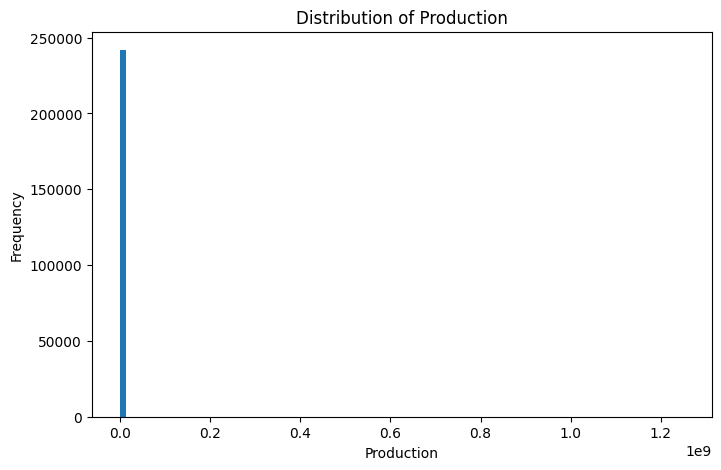

In [8]:
plt.figure(figsize=(8,5))

plt.hist(
    production["Production"],
    bins=100
)

plt.title("Distribution of Production")

plt.xlabel("Production")

plt.ylabel("Frequency")

plt.show()

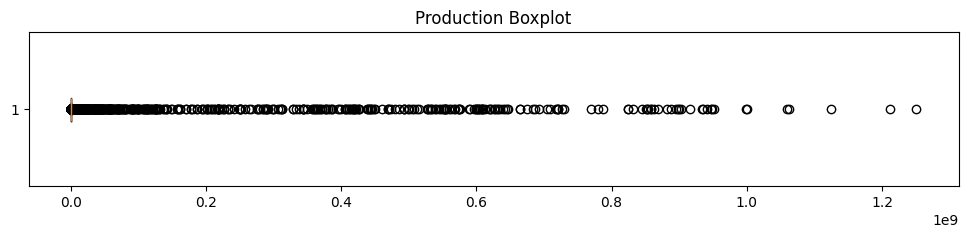

In [9]:
plt.figure(figsize=(12,2))

plt.boxplot(
    production["Production"],
    vert=False
)

plt.title("Production Boxplot")

plt.show()

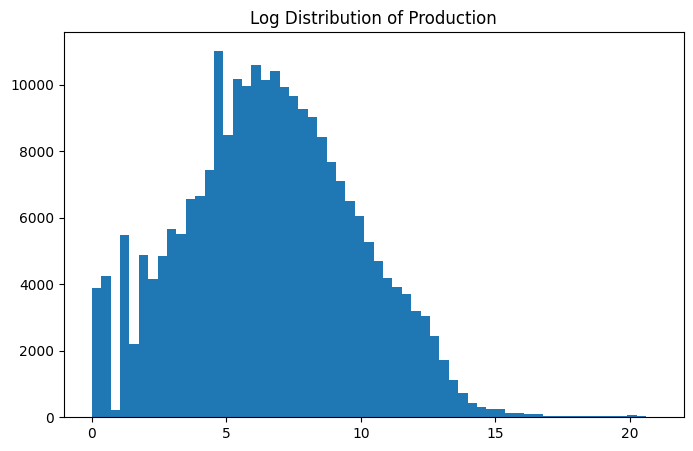

In [10]:
production["Log_Production"] = np.log1p(
    production["Production"]
)

plt.figure(figsize=(8,5))

plt.hist(
    production["Log_Production"],
    bins=60
)

plt.title("Log Distribution of Production")

plt.show()

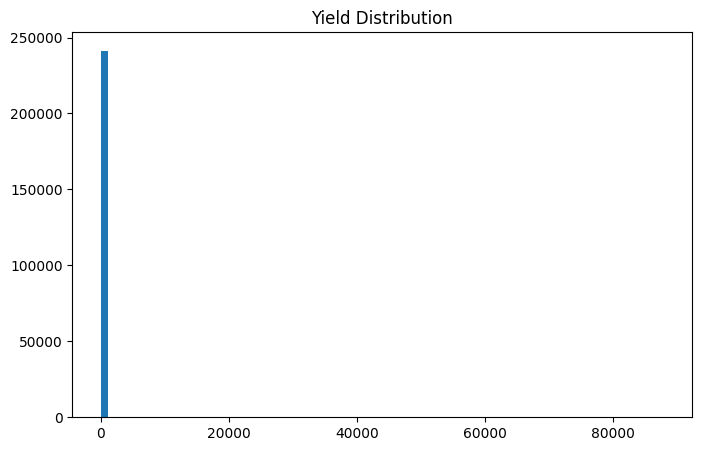

In [11]:
plt.figure(figsize=(8,5))

plt.hist(
    production["Yield"],
    bins=80
)

plt.title("Yield Distribution")

plt.show()

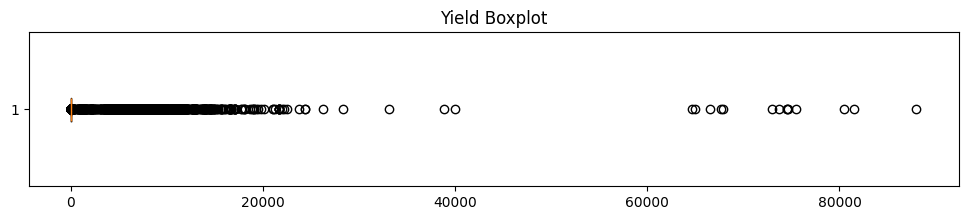

In [12]:
plt.figure(figsize=(12,2))

plt.boxplot(
    production["Yield"],
    vert=False
)

plt.title("Yield Boxplot")

plt.show()

In [13]:
crop_prod = (
    production
    .groupby("Crop")["Production"]
    .mean()
    .sort_values(ascending=False)
)

crop_prod.head(20)

Crop
Coconut            6.638490e+07
Sugarcane          7.072546e+05
Total Foodgrain    2.301636e+05
Wheat              1.691833e+05
Jute               1.289476e+05
Rice               1.064494e+05
Oilseeds Total     1.029755e+05
Cotton(Lint)       6.777727e+04
Tapioca            6.629243e+04
Paddy              6.618455e+04
Potato             6.144437e+04
Pulses Total       5.892990e+04
Banana             4.664305e+04
Atcanut (Raw)      4.636250e+04
Soyabean           4.458888e+04
Rubber             4.052817e+04
Mango              2.844217e+04
Bajra              2.410876e+04
Coffee             2.166867e+04
Maize              1.982605e+04
Name: Production, dtype: float64

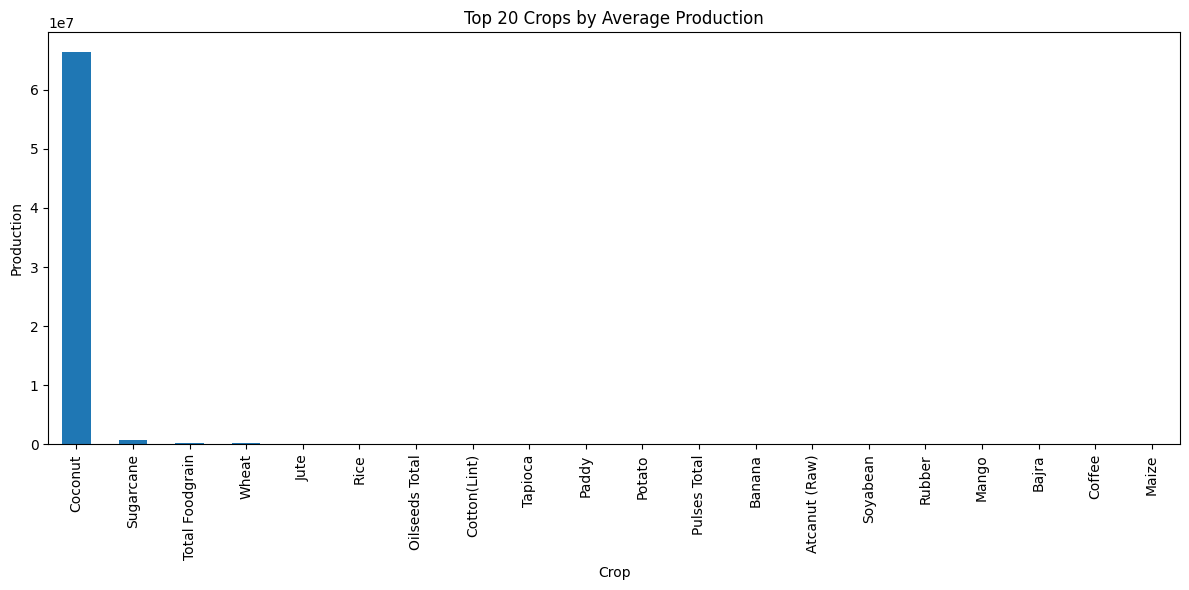

In [14]:
plt.figure(figsize=(12,6))

crop_prod.head(20).plot(kind="bar")

plt.title("Top 20 Crops by Average Production")

plt.ylabel("Production")

plt.tight_layout()

plt.show()

In [15]:
crop_yield = (
    production
    .groupby("Crop")["Yield"]
    .mean()
    .sort_values(ascending=False)
)

crop_yield.head(20)

Crop
Coconut         4040.403568
Sugarcane        195.003397
Papaya            28.659374
Banana            27.064755
Grapes            19.229891
Tapioca           18.773412
Pineapple         13.996944
Potato            12.867025
Cabbage           11.920462
Onion             11.855243
Sapota            10.267326
Cashewnut          9.675758
Colocosia          9.510370
Jute               9.456483
Sweet Potato       8.848029
Ginger             8.572291
Orange             8.463161
Jute & Mesta       8.114555
Lemon              7.932812
Tomato             7.826413
Name: Yield, dtype: float64

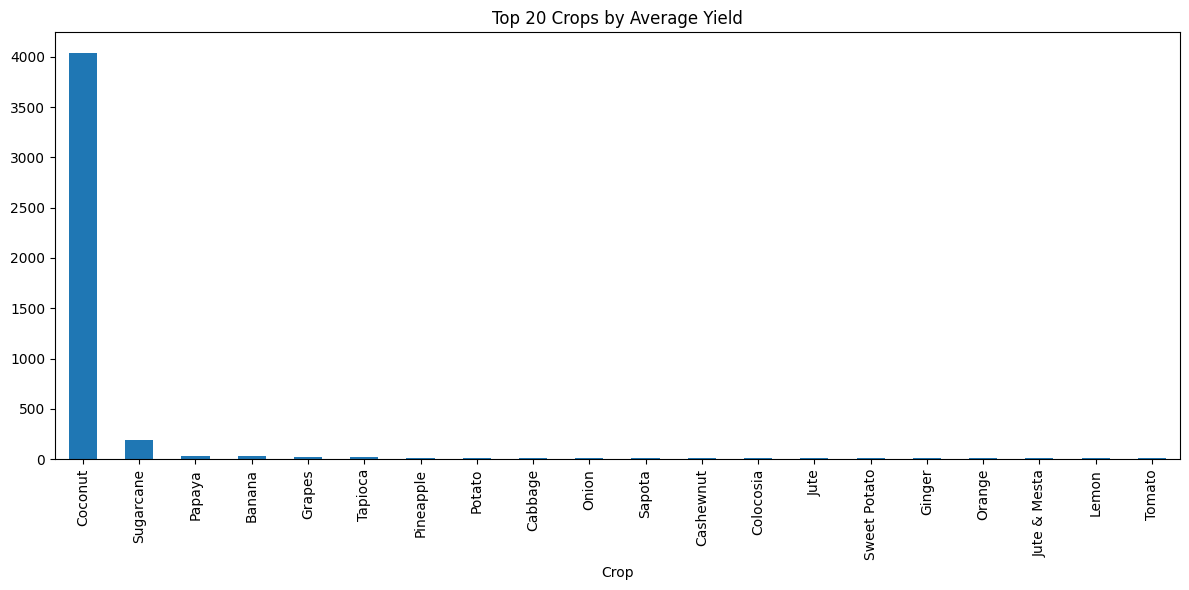

In [16]:
plt.figure(figsize=(12,6))

crop_yield.head(20).plot(kind="bar")

plt.title("Top 20 Crops by Average Yield")

plt.tight_layout()

plt.show()

In [17]:
state_prod = (
    production
    .groupby("State")["Production"]
    .mean()
    .sort_values(ascending=False)
)

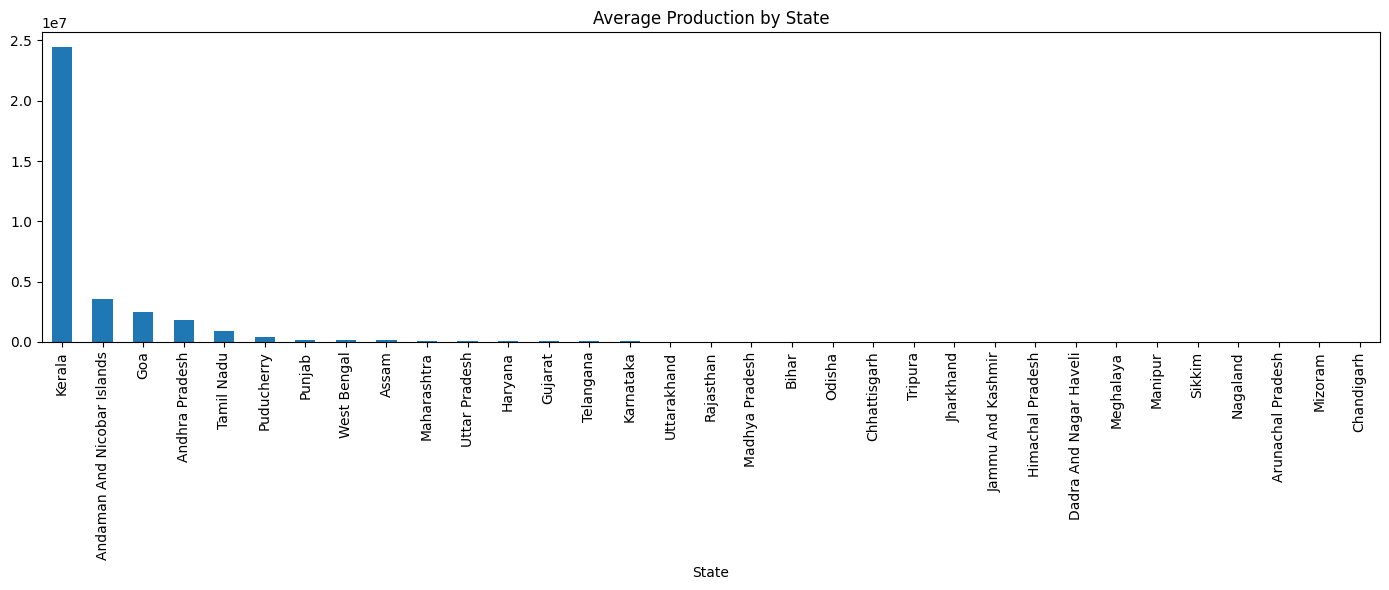

In [18]:
plt.figure(figsize=(14,6))

state_prod.plot(kind="bar")

plt.title("Average Production by State")

plt.tight_layout()

plt.show()

In [19]:
state_yield = (
    production
    .groupby("State")["Yield"]
    .mean()
    .sort_values(ascending=False)
)

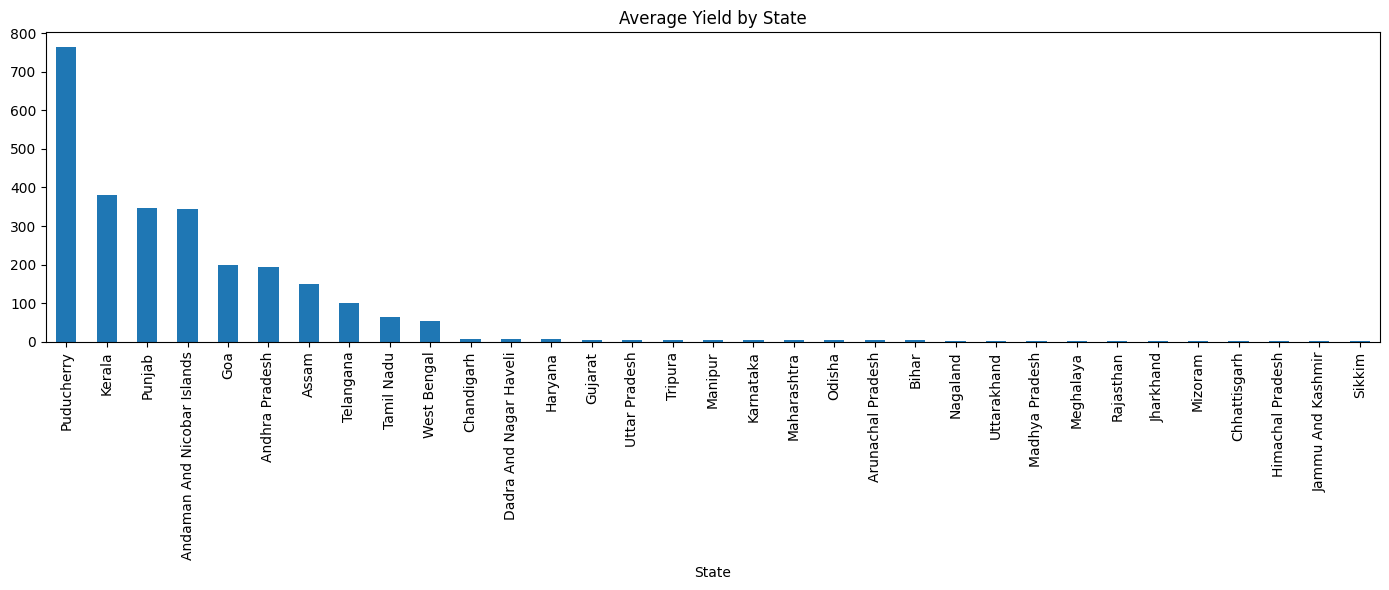

In [20]:
plt.figure(figsize=(14,6))

state_yield.plot(kind="bar")

plt.title("Average Yield by State")

plt.tight_layout()

plt.show()

In [21]:
year_prod = (
    production
    .groupby("Year")["Production"]
    .mean()
)

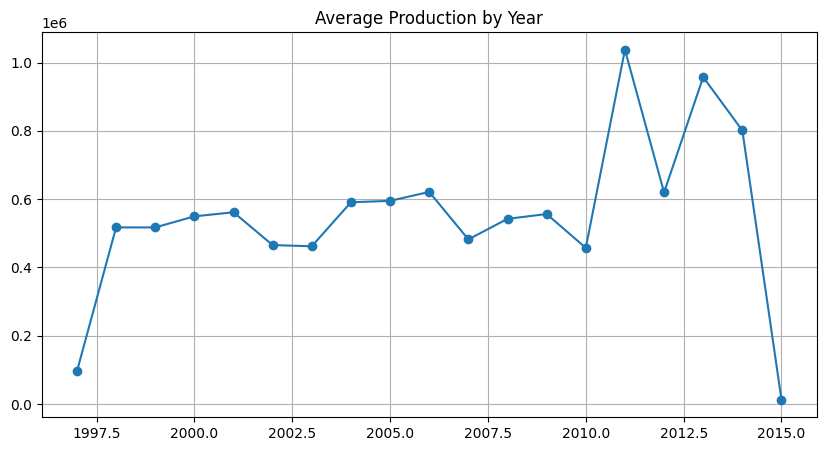

In [22]:
plt.figure(figsize=(10,5))

plt.plot(
    year_prod.index,
    year_prod.values,
    marker="o"
)

plt.title("Average Production by Year")

plt.grid()

plt.show()

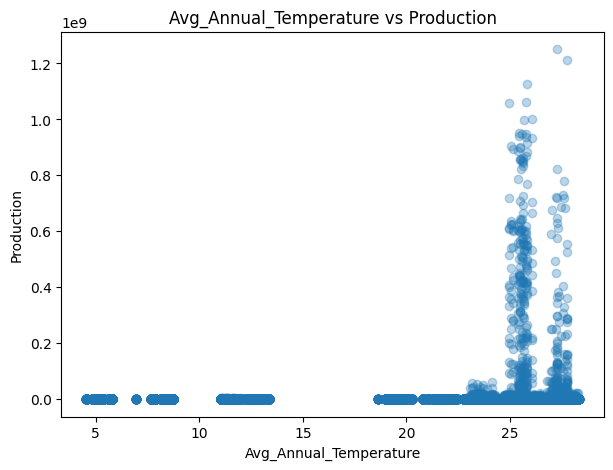

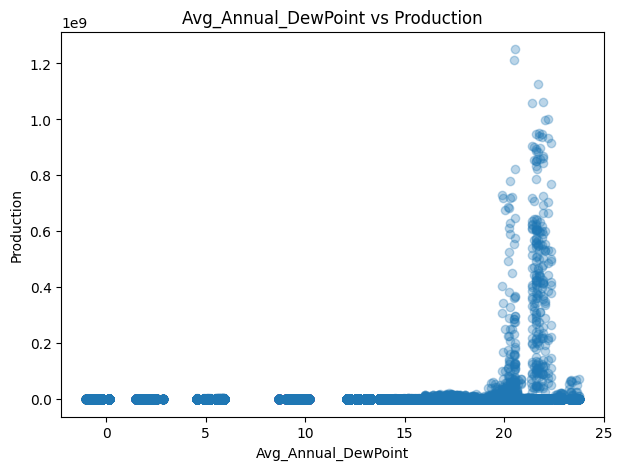

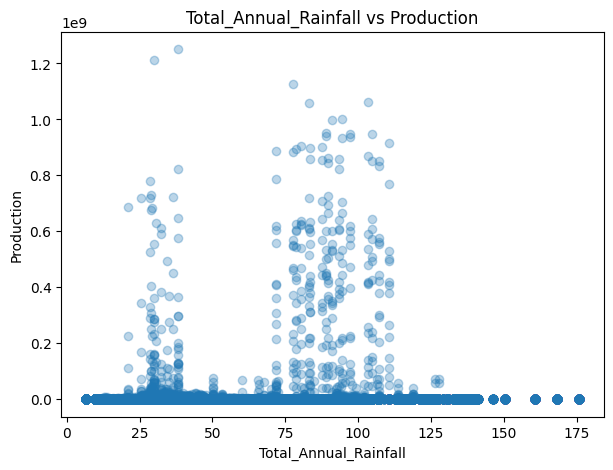

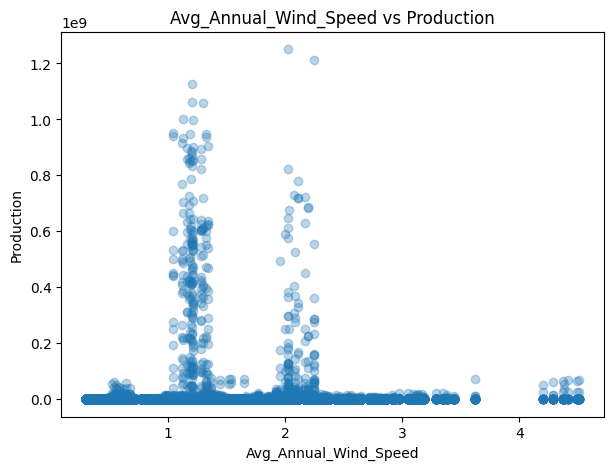

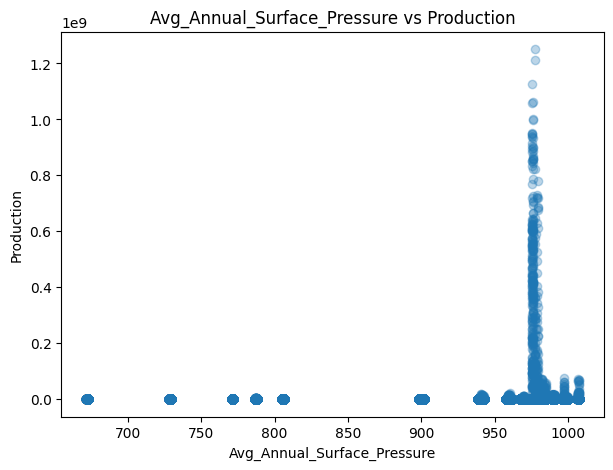

In [23]:
weather_cols = [
    "Avg_Annual_Temperature",
    "Avg_Annual_DewPoint",
    "Total_Annual_Rainfall",
    "Avg_Annual_Wind_Speed",
    "Avg_Annual_Surface_Pressure"
]

for col in weather_cols:

    plt.figure(figsize=(7,5))

    plt.scatter(
        production[col],
        production["Production"],
        alpha=0.3
    )

    plt.xlabel(col)

    plt.ylabel("Production")

    plt.title(f"{col} vs Production")

    plt.show()

In [24]:
numeric = production.select_dtypes(
    include=np.number
)

corr = numeric.corr()

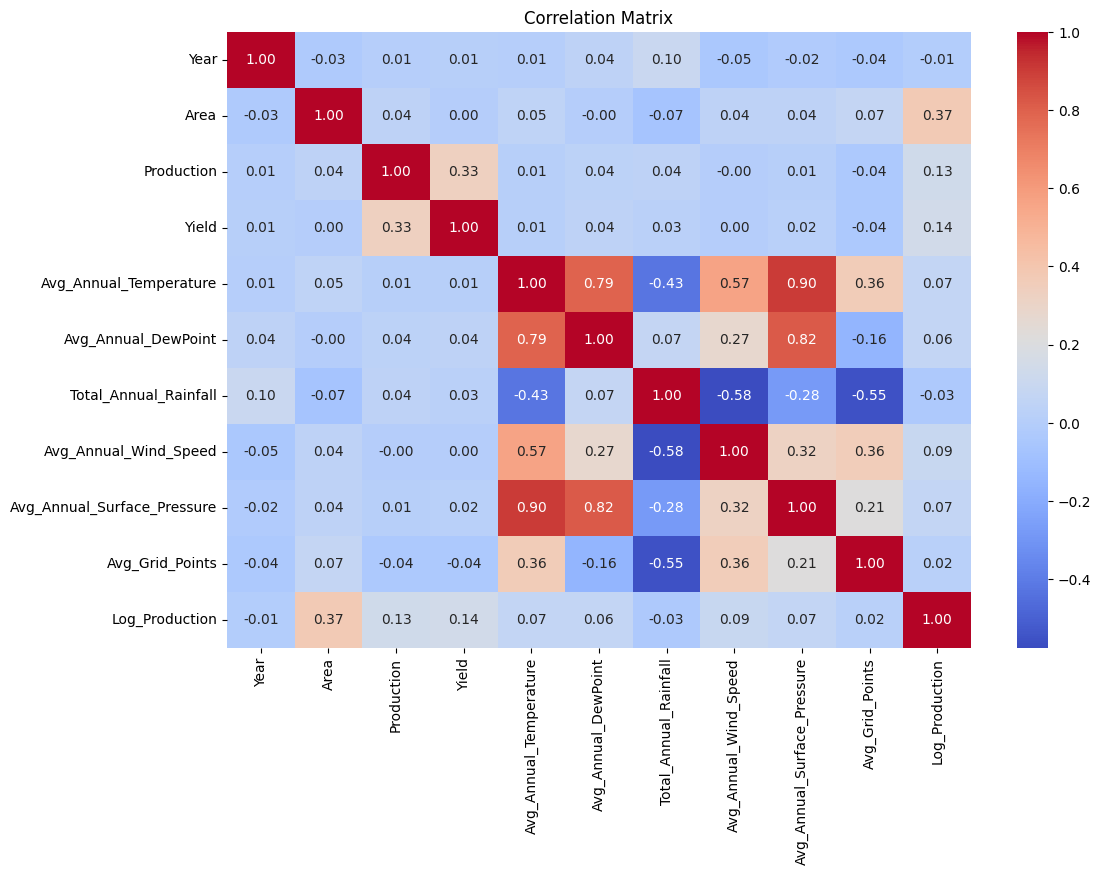

In [25]:
plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [26]:
Q1 = production["Production"].quantile(0.25)

Q3 = production["Production"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

outliers = production[
    (production["Production"] < lower) |
    (production["Production"] > upper)
]

print("Outliers:", len(outliers))

print(
    "Percentage:",
    len(outliers)/len(production)*100
)

Outliers: 42390
Percentage: 17.490437817965763


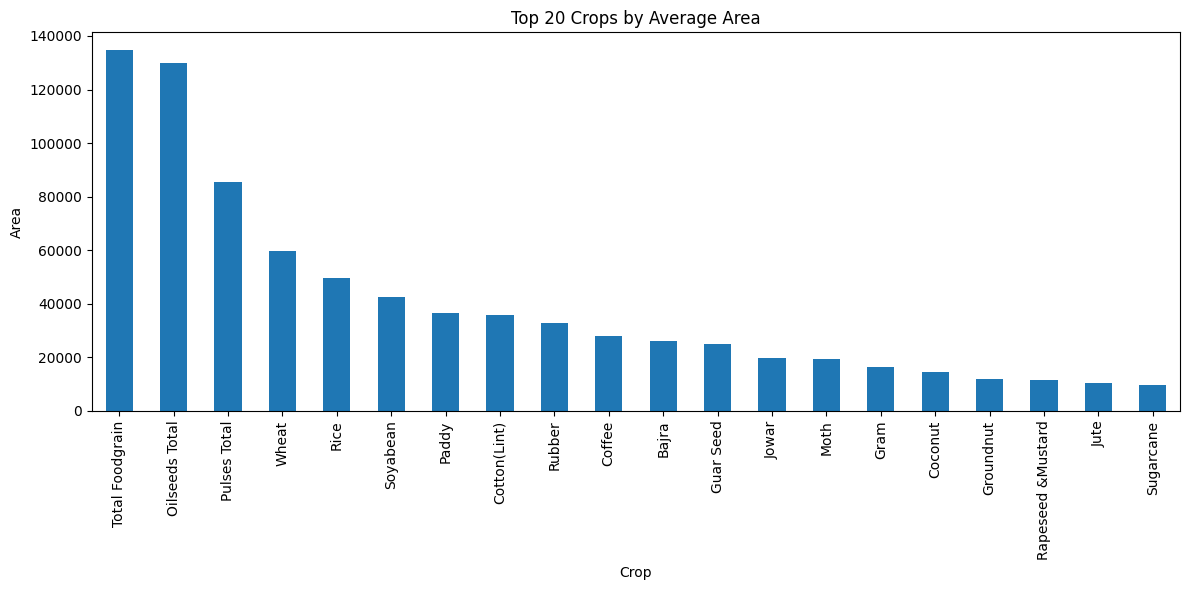

In [27]:
crop_area = (
    production
    .groupby("Crop")["Area"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

crop_area.head(20).plot(kind="bar")

plt.title("Top 20 Crops by Average Area")

plt.ylabel("Area")

plt.tight_layout()

plt.show()

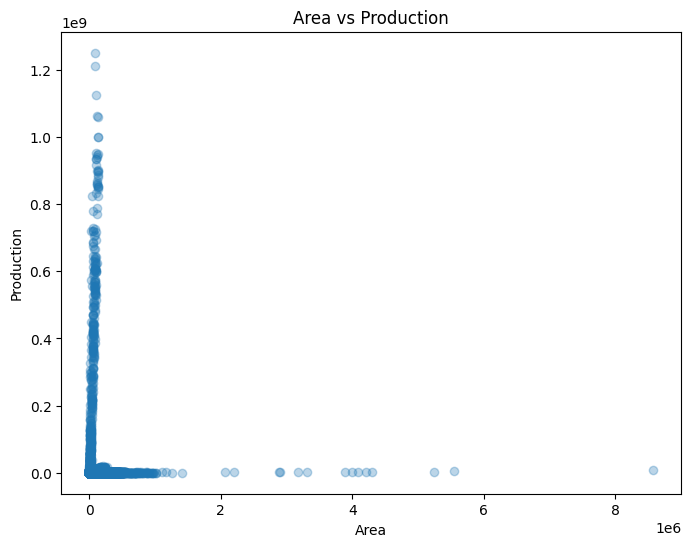

In [33]:
plt.figure(figsize=(8,6))

plt.scatter(
    production["Area"],
    production["Production"],
    alpha=0.3
)

plt.xlabel("Area")
plt.ylabel("Production")
plt.title("Area vs Production")

plt.show()

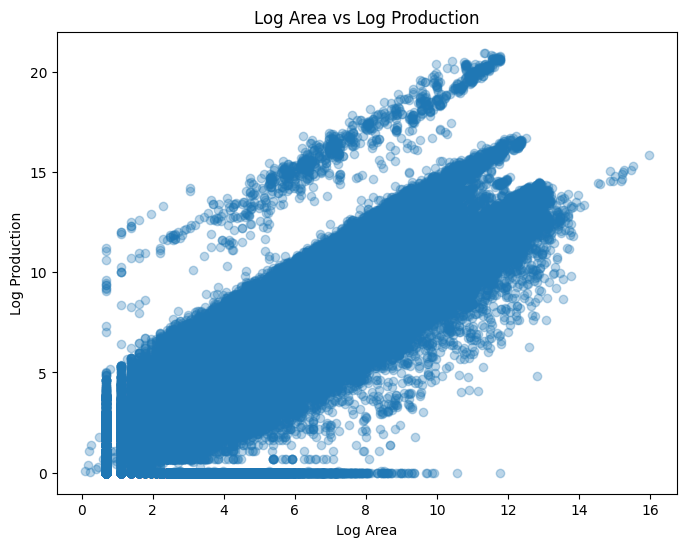

In [34]:
production["Log_Area"] = np.log1p(production["Area"])

plt.figure(figsize=(8,6))

plt.scatter(
    production["Log_Area"],
    production["Log_Production"],
    alpha=0.3
)

plt.xlabel("Log Area")
plt.ylabel("Log Production")
plt.title("Log Area vs Log Production")

plt.show()

EDA Summary

Dataset contains 242,361 observations with no missing values.\
Production and Yield are highly right-skewed.\
Log transformation produces a near-normal target distribution.\
Coconut dominates both production and yield because of its production scale.\
Weather variables show weak linear correlation with production, indicating nonlinear relationships.\
Around 17.5% of observations appear as statistical outliers but represent valid agricultural records and will be retained.\
The dataset is ready for feature engineering.\
Total Foodgrain and Oilseeds occupy the largest cultivated area.\
Wheat and Rice have both large cultivated area and high production.\
Coconut produces extremely high output despite a comparatively smaller cultivated area, indicating exceptionally high productivity.\
Cultivated area alone does not determine production, suggesting that crop type, yield, and environmental factors also play important roles.\
Raw Area vs Production is heavily affected by extreme values and is difficult to interpret.\
After log transformation, a strong positive relationship emerges between cultivated area and production.\
Multiple diagonal bands indicate that different crops have different productivity levels.\
Log_Area is expected to be one of the most important predictors of crop production.\
Log transformation substantially reduces skewness and improves the suitability of the data for machine learning models.